# Setup

## Load packages

In [1]:
# Load up necessary packages. 
import os
import glob
import importlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from scipy.ndimage import gaussian_filter1d
from mpl_toolkits.axes_grid1 import make_axes_locatable

# Import my custom utils.
import utils
importlib.reload(utils)

<module 'utils' from '/tscc/projects/ps-yeolab3/kflanagan/plip_plop/matrix_correspondance/utils.py'>

# Helper functions

In [2]:
def plot_category(category, core_size=300):

    subset = metadata[
        metadata["zoo_category"] == category
    ]

    for _, row in subset.iterrows():

        comp = comparison_data[
            row["comparison_id"]
        ]

        window_idx = row["window_idx"]

        matrix = comp[
            "correspondence_matrix"
        ][window_idx]

        island_labels = comp[
            "island_labels"
        ][window_idx]

        island_roles = comp[
            "island_roles"
        ][window_idx]

        context = (
            comp["signal_A"].shape[2] - core_size
        ) // 2

        core_start = context
        core_end = context + core_size

        signal_A = comp["signal_A"][
            window_idx,
            :,
            core_start:core_end
        ].mean(axis=0)

        signal_B = comp["signal_B"][
            window_idx,
            :,
            core_start:core_end
        ].mean(axis=0)

        title = (
            f'{row["experiment_A"]} vs '
            f'{row["experiment_B"]}\n'
            f'{row["chrom"]}:'
            f'{row["start"]}-'
            f'{row["end"]}'
        )

        plot_correspondence_matrix(
            matrix,
            signal_A,
            signal_B,
            island_labels=island_labels,
            island_roles=island_roles,
            title=title
        )

# Load results

In [3]:
INPUT_DIR = "/tscc/lustre/ddn/scratch/kflanagan/plip_plop_results/fv_processed_inputs/"

comparison_table = pd.read_csv("/tscc/nfs/home/kflanagan/projects/plip_plop/V2_feature_vectors/select_comparisons/encode_initial_30_comparisons.tsv", sep="\t")


In [4]:
# Windows currently in our test zoo.
example_windows = pd.DataFrame([
    # Easy agreement.
    ["easy_agreement", "PUM1",  "PUM2",   "chrY",  10200042,  10200342],
    ["easy_agreement", "PUM1",  "PUM2",   "chr12", 93395361,  93395661],
    ["easy_agreement", "FUS",   "TAF15",  "chr3",  146121064, 146121364],
    ["easy_agreement", "FUS",   "TAF15",  "chr14", 52646268,  52646568],

    # No agreement.
    ["no_agreement", "QKI",   "NOLC1", "chr7", 128092393, 128092693],
    ["no_agreement", "SND1",  "GRWD1", "chr2", 196720471, 196720771],
    ["no_agreement", "ILF3",  "NCBP2",  "chr4", 39527182,  39527482],

    # Pure displacement.
    ["pure_displacement", "PRPF4", "PRPF8",  "chr10", 99794312,  99794612],
    ["pure_displacement", "PRPF4", "PRPF8",  "chr16", 18815074,  18815374],
    ["pure_displacement", "CPSF6", "CSTF2T", "chr4",  173331527, 173331827],
    ["pure_displacement", "PRPF4", "PRPF8",  "chr18", 693781,     694081],
    ["pure_displacement", "FUS",   "TAF15",  "chr20", 49284292,  49284592],

    # Cross-correlation "shuffled off screen" examples.
    ["shuffled_off_screen", "PUM1", "PUM2",  "chr11", 9589488,  9589788],
    ["shuffled_off_screen", "FUS",  "TAF15", "chr6",  31670881, 31671181],
    ["shuffled_off_screen", "QKI",  "NOLC1", "chr18", 77993533, 77993833],

    # Noisy / low-confidence windows.
    ["noisy", "PRPF4", "PRPF8",  "chr12", 318089,   318389],
    ["noisy", "CPSF6", "CSTF2T", "chr16", 50273059, 50273359],
    ["noisy", "SND1",  "GRWD1",  "chr19", 798540,   798840],

], columns=[
    "zoo_category",
    "rbp_A",
    "rbp_B",
    "chrom",
    "start",
    "end"
])

In [5]:
# Keep only comparisons represented in the current zoo.
wanted_pairs = set(
    zip(
        example_windows["rbp_A"],
        example_windows["rbp_B"]
    )
)

available_pairs = set(
    (
        row["experiment_A"].split("_")[0],
        row["experiment_B"].split("_")[0]
    )
    for _, row in comparison_table.iterrows()
)

missing_pairs = wanted_pairs - available_pairs

if missing_pairs:
    print("\n" + "!" * 70)
    print("WARNING: REQUESTED ZOO COMPARISONS NOT FOUND")
    print("!" * 70)

    for rbp_A, rbp_B in sorted(missing_pairs):
        print(f"  {rbp_A} vs {rbp_B}")

    print("!" * 70 + "\n")

comparison_table = comparison_table[
    comparison_table.apply(
        lambda row: (
            row["experiment_A"].split("_")[0],
            row["experiment_B"].split("_")[0]
        ) in wanted_pairs,
        axis=1
    )
].copy()

In [6]:
comparison_data = {}
all_metadata = []

for comparison_id, row in comparison_table.iterrows():
    experiment_A = row["experiment_A"]
    experiment_B = row["experiment_B"]

    rbp_A = experiment_A.split("_")[0]
    rbp_B = experiment_B.split("_")[0]

    wanted = example_windows[
        (example_windows["rbp_A"] == rbp_A) &
        (example_windows["rbp_B"] == rbp_B)
    ]

    if wanted.empty:
        continue

    npz_file = os.path.join(INPUT_DIR, f"{experiment_A}_{experiment_B}.npz")

    if not os.path.exists(npz_file):
        print(f"Missing: {npz_file}")
        continue

    with np.load(npz_file) as data:

        # Find only the requested windows for this comparison.
        keep = np.zeros(len(data["chrom"]), dtype=bool)
        
        for _, example in wanted.iterrows():
            exact_match = (
                (data["chrom"] == example["chrom"]) &
                (data["start"] == example["start"]) &
                (data["end"] == example["end"])
            )
        
            if exact_match.any():
                keep |= exact_match
                continue
        
            # Exact window was not found.
            print("\n" + "!" * 80)
            print("WARNING: REQUESTED WINDOW NOT FOUND")
            print("!" * 80)
            print(
                f'{rbp_A} vs {rbp_B}: '
                f'{example["chrom"]}:{example["start"]}-{example["end"]}'
            )
        
            # Look for nearby windows on the same chromosome.
            same_chrom = data["chrom"] == example["chrom"]
            nearby_idx = np.where(same_chrom)[0]
        
            if len(nearby_idx) == 0:
                print(f'No windows found at all on {example["chrom"]}.')
                print("!" * 80 + "\n")
                continue
        
            nearby_starts = data["start"][nearby_idx].astype(int)
            nearby_ends = data["end"][nearby_idx].astype(int)
        
            # Coordinate distance from requested window.
            distance = (
                np.abs(nearby_starts - int(example["start"])) +
                np.abs(nearby_ends - int(example["end"]))
            )
        
            order = np.argsort(distance)
        
            print("\nClosest windows on the same chromosome:")
        
            for rank in order[:5]:
                i = nearby_idx[rank]
        
                start_diff = int(data["start"][i]) - int(example["start"])
                end_diff = int(data["end"][i]) - int(example["end"])
        
                print(
                    f'  {data["chrom"][i]}:{data["start"][i]}-{data["end"][i]}'
                    f'   '
                    f'(start {start_diff:+d}, end {end_diff:+d})'
                )
        
            print("!" * 80 + "\n")
        
        idx = np.where(keep)[0]

        print(
            f"{rbp_A} vs {rbp_B}: "
            f"found {len(idx)} / {len(wanted)} requested windows"
        )

        # Load only those windows.
        ip_A = data["ip_signals_A"][idx].astype(np.float32)
        in_A = data["in_signals_A"][idx].astype(np.float32)
        ip_B = data["ip_signals_B"][idx].astype(np.float32)
        in_B = data["in_signals_B"][idx].astype(np.float32)

        ip_A_library_sizes = data["ip_A_library_sizes"]
        in_A_library_sizes = data["in_A_library_sizes"]
        ip_B_library_sizes = data["ip_B_library_sizes"]
        in_B_library_sizes = data["in_B_library_sizes"]

        n_windows = len(ip_A)

        if not (len(ip_A) == len(in_A) == len(ip_B) == len(in_B)):
            raise ValueError(
                f"Signal arrays do not match for comparison {comparison_id}."
            )

        if in_A.shape[1] != 1 or in_B.shape[1] != 1:
            raise ValueError(
                f"Expected one IN replicate for comparison {comparison_id}."
            )

        # Convert raw coverage to RPM.
        ip_A_rpm = ip_A * (1e6 / ip_A_library_sizes[None, :, None])
        in_A_rpm = in_A * (1e6 / in_A_library_sizes[None, :, None])
        ip_B_rpm = ip_B * (1e6 / ip_B_library_sizes[None, :, None])
        in_B_rpm = in_B * (1e6 / in_B_library_sizes[None, :, None])

        # RPM corresponding approximately to one read.
        ip_A_pc = utils.calculate_rpm_pseudocount(ip_A_library_sizes)
        in_A_pc = utils.calculate_rpm_pseudocount(in_A_library_sizes)
        ip_B_pc = utils.calculate_rpm_pseudocount(ip_B_library_sizes)
        in_B_pc = utils.calculate_rpm_pseudocount(in_B_library_sizes)

        # Abundance-weighted IP/IN enrichment using the central 300-nt core
        # to define the shared A+B abundance reference.
        signal_A = np.empty_like(ip_A_rpm)
        signal_B = np.empty_like(ip_B_rpm)

        for w in range(n_windows):
            mean_A = ip_A_rpm[w, :, 150:450].mean()
            mean_B = ip_B_rpm[w, :, 150:450].mean()
            mean_AB = (mean_A + mean_B) / 2

            for r in range(ip_A.shape[1]):
                signal_A[w, r] = utils.abundance_weighted_enrichment(
                    ip_A_rpm[w, r],
                    in_A_rpm[w, 0],
                    ip_A_pc,
                    in_A_pc,
                    mean_AB
                )

            for r in range(ip_B.shape[1]):
                signal_B[w, r] = utils.abundance_weighted_enrichment(
                    ip_B_rpm[w, r],
                    in_B_rpm[w, 0],
                    ip_B_pc,
                    in_B_pc,
                    mean_AB
                )

        comparison_data[comparison_id] = {
            "signal_A": signal_A,
            "signal_B": signal_B,
            "ip_A_rpm": ip_A_rpm,
            "in_A_rpm": in_A_rpm,
            "ip_B_rpm": ip_B_rpm,
            "in_B_rpm": in_B_rpm
        }

        metadata = pd.DataFrame({
            "comparison_id": comparison_id,
            "window_idx": np.arange(n_windows),
            "original_window_idx": idx,
            "category": row["category"],
            "experiment_A": experiment_A,
            "experiment_B": experiment_B,
            "chrom": data["chrom"][idx],
            "start": data["start"][idx],
            "end": data["end"][idx],
            "strand": data["strand"][idx],
            "region_id": data["region_id"][idx],
            "block_number": data["block_number"][idx],
            "context_start": data["context_start"][idx],
            "context_end": data["context_end"][idx],
        })

        all_metadata.append(metadata)


metadata = pd.concat(all_metadata, ignore_index=True)

metadata = metadata.merge(
    example_windows[["zoo_category", "chrom", "start", "end"]],
    on=["chrom", "start", "end"],
    how="left"
)

print("Comparisons loaded:", len(comparison_data))
print("Total windows:", len(metadata))

FUS vs TAF15: found 4 / 4 requested windows
PUM1 vs PUM2: found 3 / 3 requested windows
CPSF6 vs CSTF2T: found 2 / 2 requested windows
PRPF4 vs PRPF8: found 4 / 4 requested windows
ILF3 vs NCBP2: found 1 / 1 requested windows
SND1 vs GRWD1: found 2 / 2 requested windows
QKI vs NOLC1: found 2 / 2 requested windows
Comparisons loaded: 7
Total windows: 18


In [7]:
for comparison_id, comp in comparison_data.items():
    comp["correspondence_matrix"] = utils.correspondence_matrix(
        comp["signal_A"],
        comp["signal_B"]
    )

    print(
        comparison_id,
        comp["correspondence_matrix"].shape,
        "NaN:",
        np.isnan(comp["correspondence_matrix"]).sum()
    )

0 (4, 300, 300) NaN: 0
1 (3, 300, 300) NaN: 0
18 (2, 300, 300) NaN: 0
19 (4, 300, 300) NaN: 0
26 (1, 300, 300) NaN: 0
28 (2, 300, 300) NaN: 0
29 (2, 300, 300) NaN: 0


# Get islands

# I AM REMAKING THIS SECTION TO BE CLOSER TO HOW I PROCESSED THE SIMULATION. 

In [12]:
comparison_data[0]['signal_A']
# Ok, so all 4 of the signal A runs are in here, and I assume the order must be matched to the signal B runs. 

4

In [ ]:
###!!!### Take these and rework for my signal. 
###!!!### Is the simulated and real signal identical? 

def plot_islands(result, title=None):
    matrix = result["matrix"]
    signal_a = result["signal_a"]
    signal_b = result["signal_b"]
    labels = result["island_labels"]
    islands = result["islands"]
    modes = result["modes"]
    n = len(signal_a)

    fig = plt.figure(figsize=(10.5, 10))
    grid = fig.add_gridspec(3, 3, width_ratios=(1, 4, 0.18), height_ratios=(1.2, 1, 4), wspace=0.10, hspace=0.10)
    fig.subplots_adjust(right=0.78)
    ax = fig.add_subplot(grid[2, 1])
    ax_overlay = fig.add_subplot(grid[0, 1], sharex=ax)
    ax_top = fig.add_subplot(grid[1, 1], sharex=ax)
    ax_left = fig.add_subplot(grid[2, 0], sharey=ax)
    ax_colorbar = fig.add_subplot(grid[2, 2])

    image = ax.imshow(matrix, origin="lower", aspect="equal")
    ax.plot([-0.5, n - 0.5], [-0.5, n - 0.5], "--", color="white", lw=1)
    ax.set(xlim=(-0.5, n - 0.5), ylim=(-0.5, n - 0.5), xlabel="B position", ylabel="A position")

    island_lookup = {island["island_id"]: island for island in islands}
    mode_colors = ["#ff2d2d", "#ff8c00", "#ffcc00", "#d81b60", "#b23aee",
                   "#ff5e00", "#c1121f", "#ff4d8d", "#e76f00", "#8b1e3f"]
    island_mode_colors = {}
    for color_index, mode in enumerate(modes):
        color = mode_colors[color_index % len(mode_colors)]
        for island_id in mode["islands"]:
            island_mode_colors.setdefault(island_id, []).append(color)
    selected_island_ids = set(island_mode_colors)
    handles = []

    # Keep every detected ridge visible for displacement diagnostics.
    for island in islands:
        if island["island_id"] in selected_island_ids:
            continue
        ridge = island["ridge"]
        axis_x, axis_y = ridge[:, 1], ridge[:, 0]
        if len(axis_x) == 1:
            ax.plot(axis_x, axis_y, "o", color="black", ms=5)
            ax.plot(axis_x, axis_y, "o", color="#eeeeee", ms=3)
        else:
            ax.plot(axis_x, axis_y, color="black", lw=3)
            ax.plot(axis_x, axis_y, color="#eeeeee", lw=1.3)

    if len(selected_island_ids) < len(islands):
        handles.append(ax.plot([], [], color="#eeeeee", lw=1.3, label="unselected ridge")[0])

    # Nested outlines preserve every color when one broad ridge supports more
    # than one distinct, narrower lag hypothesis.
    for island_id, colors in island_mode_colors.items():
        mask = labels == island_id
        island = island_lookup[island_id]
        ridge = island["ridge"]
        axis_x, axis_y = ridge[:, 1], ridge[:, 0]
        widths = np.linspace(2 + 1.5 * (len(colors) - 1), 2, len(colors))
        ridge_widths = np.linspace(1.5 + 1.2 * (len(colors) - 1), 1.3, len(colors))

        if mask.any() and (~mask).any():
            for color, width in zip(colors, widths):
                ax.contour(mask.astype(float), levels=[0.5], colors=color,
                           linewidths=width, origin="lower")
        if len(axis_x) == 1:
            ax.plot(axis_x, axis_y, "o", color="black", ms=5 + 1.5 * len(colors))
            for color, marker_size in zip(colors, np.linspace(4 + len(colors), 3, len(colors))):
                ax.plot(axis_x, axis_y, "o", color=color, ms=marker_size)
        else:
            ax.plot(axis_x, axis_y, color="black", lw=max(ridge_widths) + 1.5)
            for color, width in zip(colors, ridge_widths):
                ax.plot(axis_x, axis_y, color=color, lw=width)

    for color_index, mode in enumerate(modes):
        color = mode_colors[color_index % len(mode_colors)]
        handles.append(ax.plot([], [], color=color, lw=2,
                               label=(f"mode {mode['mode_id']} "
                                      f"(lag {mode['lag_min']:+.1f} to {mode['lag_max']:+.1f})"))[0])

    if handles:
        ax.legend(handles=handles, loc="upper left", bbox_to_anchor=(1.28, 1))

    positions = np.arange(n)
    track_colors = {"A": "C0", "B": "C1"}
    ax_overlay.plot(positions, signal_a, label="A", color=track_colors["A"], lw=1.5)
    ax_overlay.plot(positions, signal_b, label="B", color=track_colors["B"], lw=1.5)
    ax_overlay.set_ylabel("Overlay")
    ax_overlay.legend(loc="upper right")
    ax_overlay.tick_params(axis="x", bottom=False, labelbottom=False)

    ax_top.plot(positions, signal_b, color=track_colors["B"])
    ax_top.set_ylabel("B")
    ax_top.tick_params(axis="x", bottom=False, labelbottom=False)

    ax_left.plot(signal_a, positions, color=track_colors["A"])
    ax_left.invert_xaxis()
    ax_left.set_xlabel("A")
    ax_left.tick_params(axis="y", left=False, labelleft=False)

    fig.colorbar(image, cax=ax_colorbar, label="Shared signal")
    fig.canvas.draw()
    matrix_position = ax.get_position()
    for track_axis in (ax_overlay, ax_top):
        track_position = track_axis.get_position()
        track_axis.set_position([matrix_position.x0, track_position.y0, matrix_position.width, track_position.height])
    if title is not None:
        fig.suptitle(title)
    plt.show()
    return fig, {"matrix": ax, "signal_a": ax_left, "signal_b": ax_top, "overlay": ax_overlay}


def identify_islands(signal_a, signal_b, seed_threshold_fraction=0.4, growth_threshold_fraction=0.39, max_weak_distance=2, gap_tolerance=1, shape_balance_power=1.05, ridge_fraction=0.9, split_prominence_fraction=0.25, split_min_peak_fraction=0.5, split_min_peak_distance=8, split_smoothing=4.0, split_min_seed_area=5, displacement_fold_threshold=2.0, mode_score_fraction=0.33, title=None, plot=True):
    signal_a = np.asarray(signal_a, dtype=float)
    signal_b = np.asarray(signal_b, dtype=float)

    if signal_a.ndim != 1 or signal_b.ndim != 1:
        raise ValueError("signal_a and signal_b must be one-dimensional.")
    if len(signal_a) != len(signal_b):
        raise ValueError("signal_a and signal_b must have the same length.")

    matrix = correspondence_matrix(signal_a[None, None, :], signal_b[None, None, :],
                                   core_size=len(signal_a))[0]
    seed_mask, island_mask, labels, islands = correspondence_islands(
        matrix, seed_threshold_fraction=seed_threshold_fraction,
        growth_threshold_fraction=growth_threshold_fraction,
        max_weak_distance=max_weak_distance, gap_tolerance=gap_tolerance,
        shape_balance_power=shape_balance_power, ridge_fraction=ridge_fraction,
        split_prominence_fraction=split_prominence_fraction,
        split_min_peak_fraction=split_min_peak_fraction,
        split_min_peak_distance=split_min_peak_distance,
        split_smoothing=split_smoothing, split_min_seed_area=split_min_seed_area)
    conflicts = island_conflicts(labels, islands)
    selection = select_correspondence_modes(
        islands, conflicts, displacement_fold_threshold=displacement_fold_threshold,
        mode_score_fraction=mode_score_fraction)

    result = {
        "signal_a": signal_a,
        "signal_b": signal_b,
        "matrix": matrix,
        "seed_mask": seed_mask,
        "island_mask": island_mask,
        "island_labels": labels,
        "islands": islands,
        "conflicts": conflicts,
        "selection": selection,
        "modes": selection["modes"],
        "island_modes": selection["island_modes"],
    }

    if plot:
        result["figure"], result["axes"] = plot_simulated_islands(result, title=title)

    return result

## Make initial islands

In [65]:
for comparison_id, comp in comparison_data.items():

    comp["seed_masks"] = []
    comp["island_masks"] = []
    comp["island_labels"] = []
    comp["islands"] = []

    for matrix in comp["correspondence_matrix"]:

        seed_mask, island_mask, labels, islands = utils.correspondence_islands(
            matrix,
            seed_threshold_fraction=0.4,
            growth_threshold_fraction=0.39,
            max_weak_distance=2,
            gap_tolerance=1
        )

        comp["seed_masks"].append(seed_mask)
        comp["island_masks"].append(island_mask)
        comp["island_labels"].append(labels)
        comp["islands"].append(islands)

## Organize island metadata

In [66]:
island_records = []

for _, row in metadata.iterrows():
    comp = comparison_data[row["comparison_id"]]
    islands = comp["islands"][row["window_idx"]]

    for island in islands:
        island_records.append({
            "zoo_category": row["zoo_category"],
            "experiment_A": row["experiment_A"],
            "experiment_B": row["experiment_B"],
            "chrom": row["chrom"],
            "start": row["start"],
            "end": row["end"],
            **island
        })

island_df = pd.DataFrame(island_records)

island_df.head()

,zoo_category,experiment_A,experiment_B,chrom,start,end,island_id,A_min,A_max,B_min,...,A_center,B_center,displacement,abs_displacement,area,max_support,mean_support,total_support,seed_area,zero_lag_distance
0,easy_agreement,FUS_HepG2_ENCSR464OSH,TAF15_HepG2_ENCSR841EQA,chr14,52646268,52646568,1,148,193,145,...,170.5,169.0,-1.5,1.5,2254,1.456793,1.015272,2288.423340,2254,0.0
1,easy_agreement,FUS_HepG2_ENCSR464OSH,TAF15_HepG2_ENCSR841EQA,chr14,52646268,52646568,2,148,193,281,...,170.5,290.0,119.5,119.5,874,1.361766,0.860404,751.992859,736,97.0
2,easy_agreement,FUS_HepG2_ENCSR464OSH,TAF15_HepG2_ENCSR841EQA,chr14,52646268,52646568,3,281,296,145,...,288.5,169.0,-119.5,119.5,784,0.796840,0.675073,529.257446,784,95.5
3,easy_agreement,FUS_HepG2_ENCSR464OSH,TAF15_HepG2_ENCSR841EQA,chr14,52646268,52646568,4,281,296,281,...,288.5,290.0,1.5,1.5,304,0.796840,0.646700,196.596680,256,0.0
4,pure_displacement,FUS_HepG2_ENCSR464OSH,TAF15_HepG2_ENCSR841EQA,chr20,49284292,49284592,1,0,108,24,...,54.0,70.0,16.0,16.0,10134,1.171710,0.712293,7218.380859,9360,0.0


## distinguish overlapping vs seperate islands

In [67]:
for comparison_id, comp in comparison_data.items():

    comp["island_conflicts"] = []

    for labels, islands in zip(
        comp["island_labels"],
        comp["islands"]
    ):
        conflicts = utils.island_conflicts(
            labels,
            islands
        )

        comp["island_conflicts"].append(conflicts)

## Find viable Island combinations

In [68]:
for comparison_id, comp in comparison_data.items():

    comp["compatible_island_sets"] = []
    comp["island_explanations"] = []

    for islands, conflicts in zip(
        comp["islands"],
        comp["island_conflicts"]
    ):

        compatible_sets = utils.compatible_island_sets(
            islands,
            conflicts
        )

        explanations = utils.summarize_island_sets(
            compatible_sets,
            islands,
            zero_lag_threshold=10
        )

        comp["compatible_island_sets"].append(
            compatible_sets
        )

        comp["island_explanations"].append(
            explanations
        )

In [69]:
comparison_id = list(comparison_data.keys())[0]
window_idx = 0

pd.DataFrame(
    comparison_data[comparison_id][
        "island_explanations"
    ][window_idx]
)
###!!!### This feels a bit wonky, like, 1 alone should not have an option to be what we find, cause 5 is just 1 alone but better. 

,explanation_id,islands,n_islands,total_support,zero_lag,zero_lag_islands,min_zero_lag_distance
0,1,"(1,)",1,2288.423340,True,"(1,)",0.0
1,2,"(2,)",1,751.992859,False,(),97.0
2,3,"(3,)",1,529.257446,False,(),95.5
3,4,"(4,)",1,196.596680,True,"(4,)",0.0
4,5,"(1, 4)",2,2485.020020,True,"(1, 4)",0.0
5,6,"(2, 3)",2,1281.250244,False,(),95.5


## Identify "best" island

In [70]:
for comparison_id, comp in comparison_data.items():

    comp["selection_results"] = []
    comp["classified_explanations"] = []
    comp["island_roles"] = []
    comp["zero_lag_gate_records"] = []

    for islands, conflicts in zip(
        comp["islands"],
        comp["island_conflicts"]
    ):

        result = utils.select_correspondence_islands(
            islands,
            conflicts,
            zero_lag_threshold=10,
            displacement_fold_threshold=2.0,
            co_main_fraction=0.95,
            alternative_fraction=0.33
        )

        comp["selection_results"].append(
            result
        )

        comp["classified_explanations"].append(
            result["explanations"]
        )

        comp["island_roles"].append(
            result["island_roles"]
        )

        comp["zero_lag_gate_records"].append(
            result["gate_records"]
        )

In [71]:
pd.DataFrame(comparison_data)

,0,1,18,19,26,28,29
signal_A,"[[[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0...","[[[0.09933433892725797, 0.07614456147857558, 0...","[[[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0...","[[[0.005685957528633538, 0.005685957528633538,...","[[[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0...","[[[0.0448977500345764, 0.0448977500345764, 0.0...","[[[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0..."
signal_B,"[[[0.3090979677934567, 0.3090979677934567, 0.3...","[[[1.1306970955036586, 1.1347311968465983, 1.2...","[[[1.202903280694844, 1.3625397235071395, 1.36...","[[[0.19706428572507242, 0.1133882868979487, 0....","[[[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0...","[[[0.5997507932346032, 0.5013019180205426, 0.5...","[[[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0..."
ip_A_rpm,"[[[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0...","[[[0.3260636181638521, 0.27171968180321004, 0....","[[[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0...","[[[0.05652868109825052, 0.05652868109825052, 0...","[[[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0...","[[[0.10786103055390199, 0.10786103055390199, 0...","[[[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0..."
in_A_rpm,"[[[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0...","[[[0.03176315057165889, 0.03176315057165889, 0...","[[[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0...","[[[0.05028858102219587, 0.05028858102219587, 0...","[[[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0...","[[[0.08748101224629194, 0.08748101224629194, 0...","[[[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0..."
ip_B_rpm,"[[[0.08685359267931912, 0.08685359267931912, 0...","[[[4.115060497065252, 4.256959134895088, 4.256...","[[[0.462300795550324, 0.5393509281420447, 0.53...","[[[0.21521566115757618, 0.14347710743838413, 0...","[[[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0...","[[[0.1943003707195559, 0.16654317490247647, 0....","[[[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0..."
in_B_rpm,"[[[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0...","[[[0.2783012030729091, 0.30149296999565156, 0....","[[[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0...","[[[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0...","[[[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0...","[[[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0...","[[[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0..."
correspondence_matrix,"[[[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0...","[[[0.35890988, 0.35890988, 0.35890988, 0.35890...","[[[0.14610562, 0.14610562, 0.14610562, 0.14610...","[[[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0...","[[[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0...","[[[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0...","[[[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0..."
seed_masks,"[[[False, False, False, False, False, False, F...","[[[True, True, True, True, True, True, True, T...","[[[True, True, True, True, True, True, True, T...","[[[False, False, False, False, False, False, F...","[[[False, False, False, False, False, False, F...","[[[False, False, False, False, False, False, F...","[[[False, False, False, False, False, False, F..."
island_masks,"[[[False, False, False, False, False, False, F...","[[[True, True, True, True, True, True, True, T...","[[[True, True, True, True, True, True, True, T...","[[[False, False, False, False, False, False, F...","[[[False, False, False, False, False, False, F...","[[[False, False, False, False, False, False, F...","[[[False, False, False, False, False, False, F..."
island_labels,"[[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0...","[[[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1...","[[[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1...","[[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0...","[[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0...","[[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0...","[[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0..."


In [72]:
list(comparison_data.keys())

[0, 1, 18, 19, 26, 28, 29]

In [73]:
comparison_id = list(comparison_data.keys())[1]
window_idx = 0

pd.DataFrame(
    comparison_data[comparison_id][
        "island_explanations"
    ][window_idx]
)

,explanation_id,islands,n_islands,total_support,zero_lag,zero_lag_islands,min_zero_lag_distance
0,1,"(1,)",1,4814.304199,True,"(1,)",0.0


# Make heatmaps

## Function

In [74]:
from mpl_toolkits.axes_grid1 import make_axes_locatable


def plot_correspondence_matrix(
    matrix,
    signal_A,
    signal_B,
    island_labels=None,
    island_roles=None,
    title=None
):
    n = matrix.shape[0]
    positions = np.arange(n)

    fig, ax = plt.subplots(figsize=(9, 8))

    im = ax.imshow(
        matrix,
        origin="lower",
        aspect="equal"
    )

    ax.set_xlim(-0.5, n - 0.5)
    ax.set_ylim(-0.5, n - 0.5)

    # Zero-lag diagonal.
    ax.plot(
        [-0.5, n - 0.5],
        [-0.5, n - 0.5],
        linestyle="--",
        linewidth=1
    )

    if island_labels is not None and island_roles is not None:
    
        for island_id, role in island_roles.items():
    
            if role == "main":
                color = "red"
                linewidth = 2.5
    
            elif role == "co-main":
                color = "purple"
                linewidth = 2.5
    
            elif role == "alternative":
                color = "orange"
                linewidth = 2.0
    
            else:
                # ignored and deleted islands are not plotted
                continue
    
            island_mask = island_labels == island_id
    
            ax.contour(
                island_mask.astype(float),
                levels=[0.5],
                colors=color,
                linewidths=linewidth,
                origin="lower"
            )

    ax.set_xlabel("B position")

    ax.yaxis.tick_right()
    ax.yaxis.set_label_position("right")
    ax.set_ylabel("A position")

    divider = make_axes_locatable(ax)

    # B signal across top.
    ax_top = divider.append_axes(
        "top",
        size="25%",
        pad=0.08,
        sharex=ax
    )

    ax_top.plot(
        positions,
        signal_B
    )

    ax_top.set_xlim(-0.5, n - 0.5)
    ax_top.set_ylabel("B")

    ax_top.tick_params(
        axis="x",
        bottom=False,
        labelbottom=False
    )

    ax_top.spines["top"].set_visible(False)
    ax_top.spines["right"].set_visible(False)

    # A signal down left side.
    ax_left = divider.append_axes(
        "left",
        size="25%",
        pad=0.08,
        sharey=ax
    )

    ax_left.plot(
        signal_A,
        positions
    )

    ax_left.set_ylim(-0.5, n - 0.5)
    ax_left.invert_xaxis()
    ax_left.set_xlabel("A")

    ax_left.tick_params(
        axis="y",
        left=False,
        labelleft=False
    )

    ax_left.spines["top"].set_visible(False)
    ax_left.spines["left"].set_visible(False)

    # Colorbar.
    cax = divider.append_axes(
        "right",
        size="4%",
        pad=0.9
    )

    fig.colorbar(
        im,
        cax=cax,
        label="Shared signal"
    )

    if title is not None:
        fig.suptitle(title)

    plt.show()

## Easy agreement

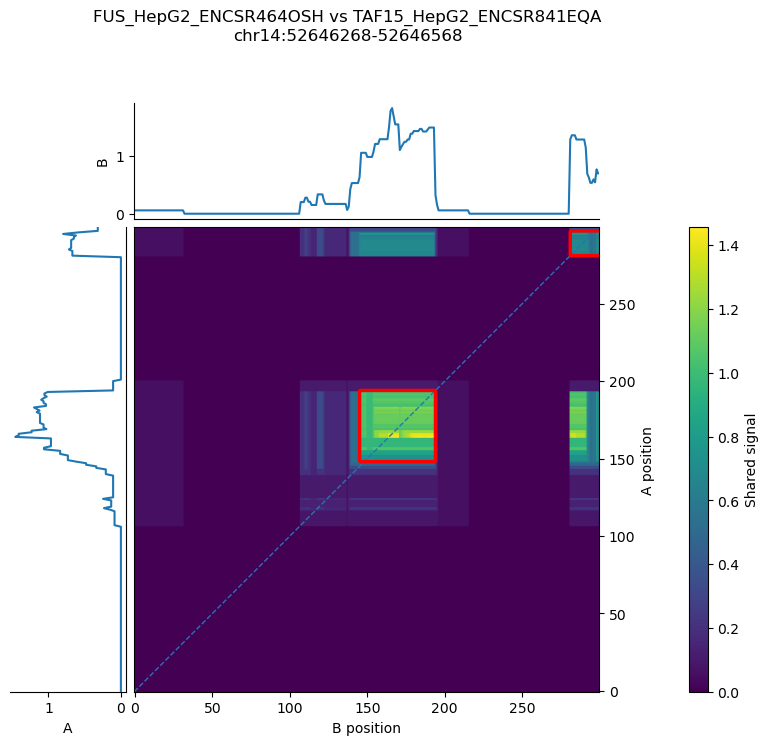

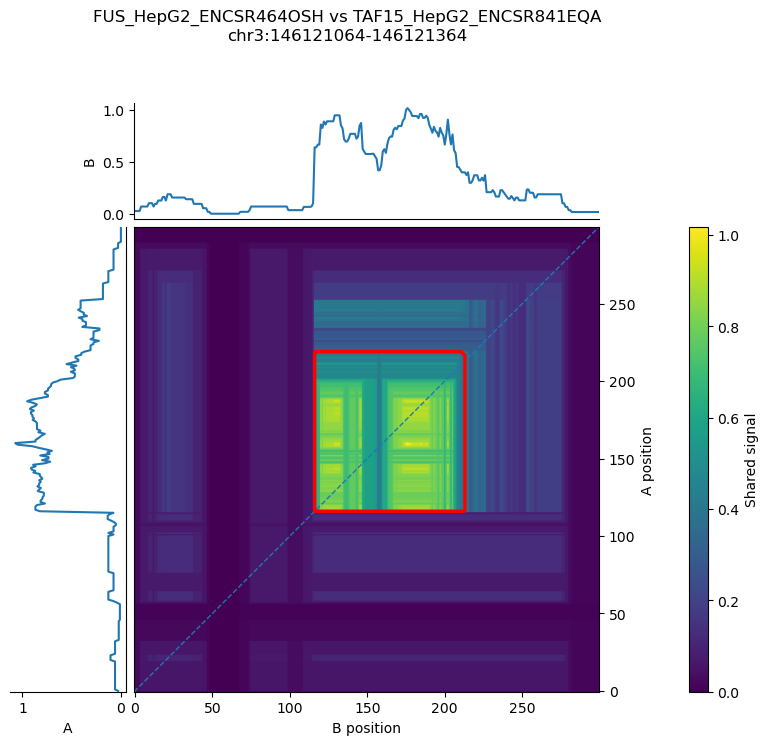

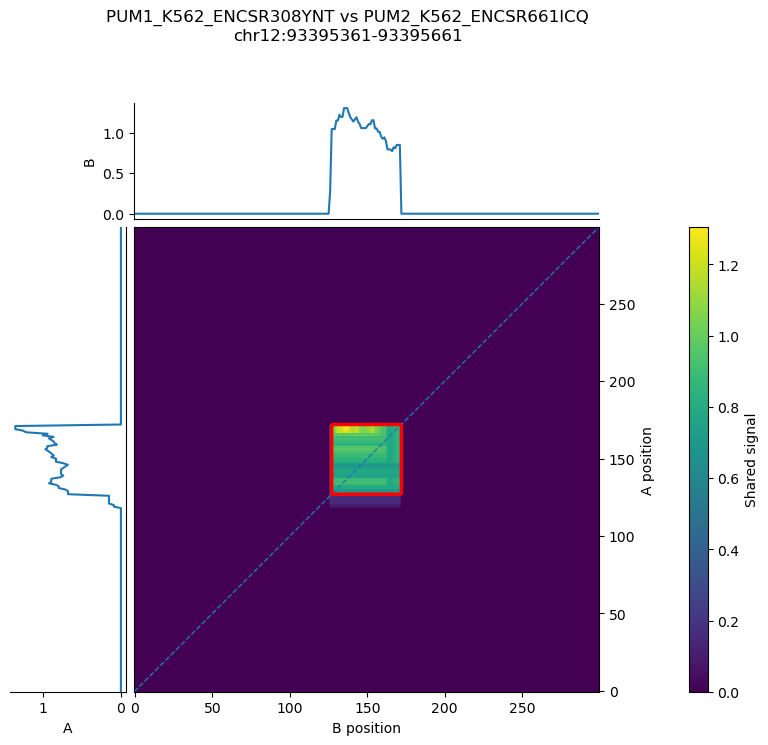

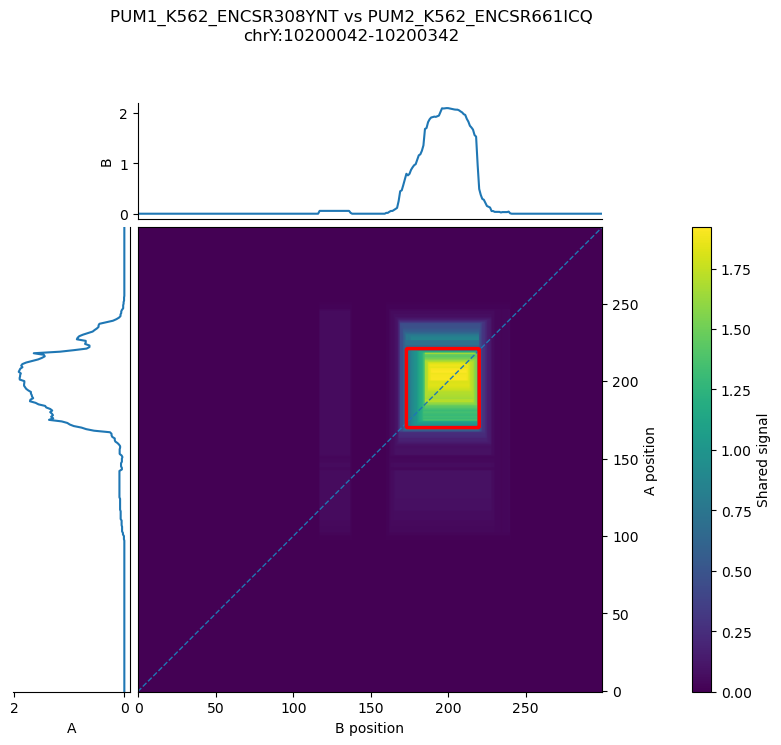

In [75]:
plot_category("easy_agreement")

## No agreement

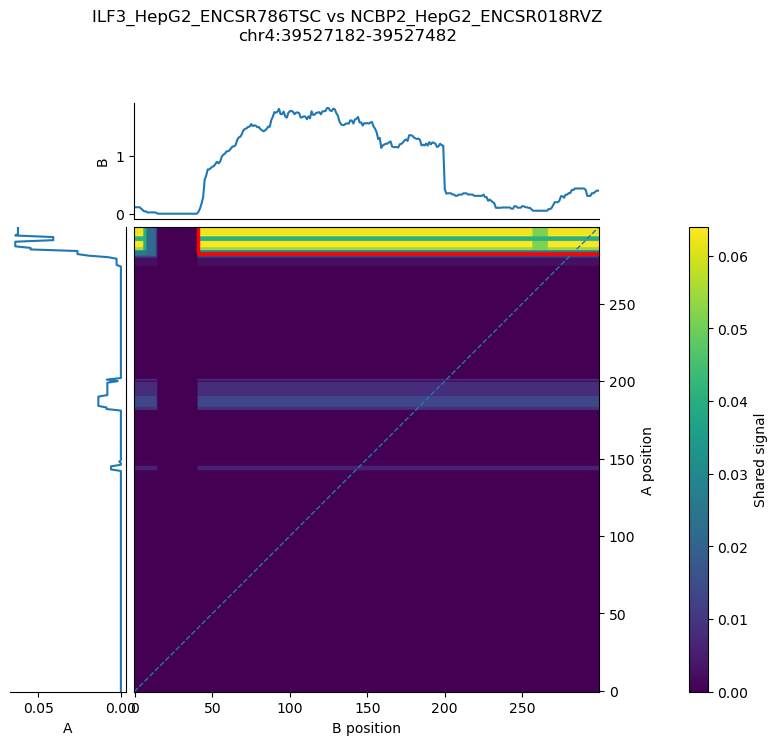

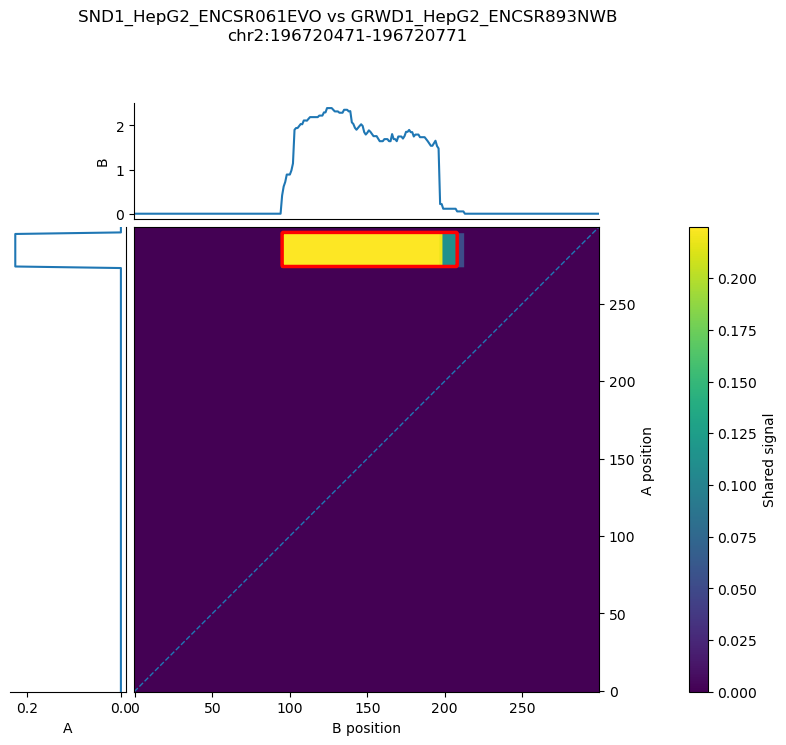

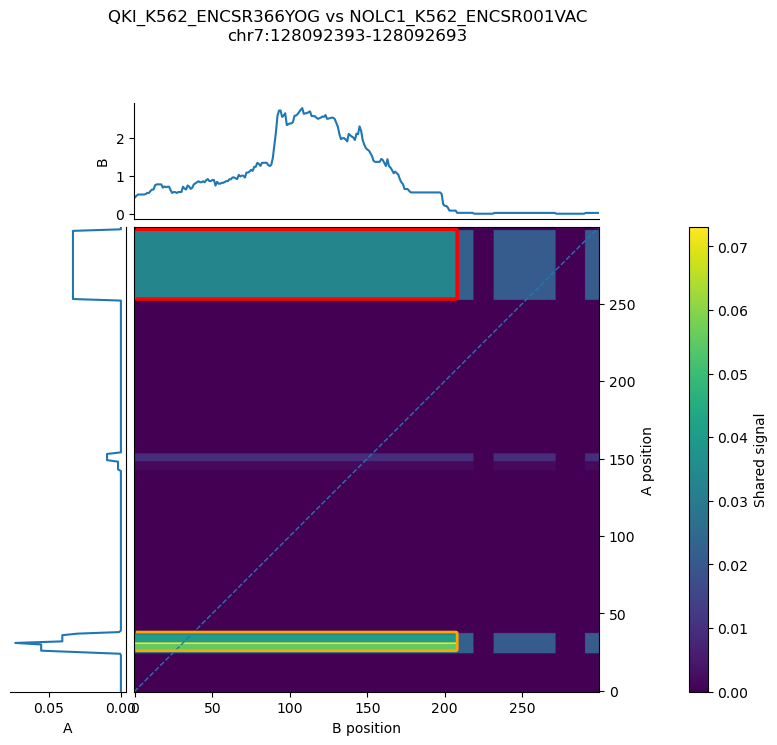

In [76]:
plot_category("no_agreement")

## Pure displacement

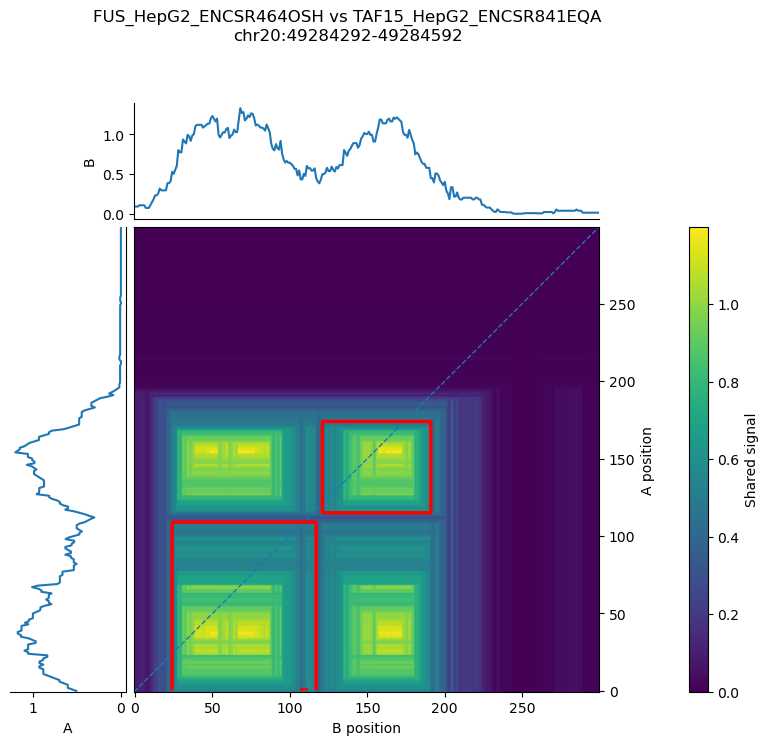

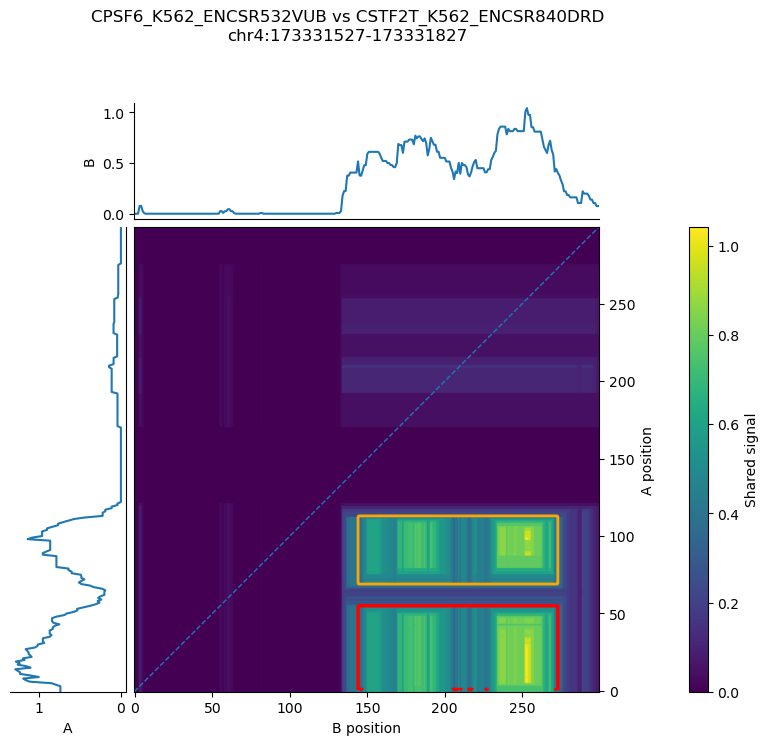

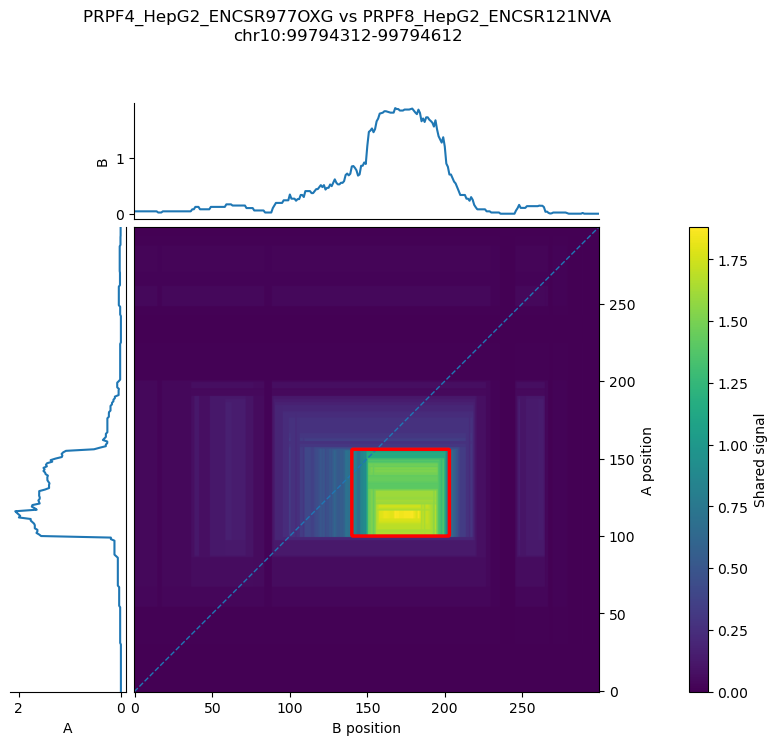

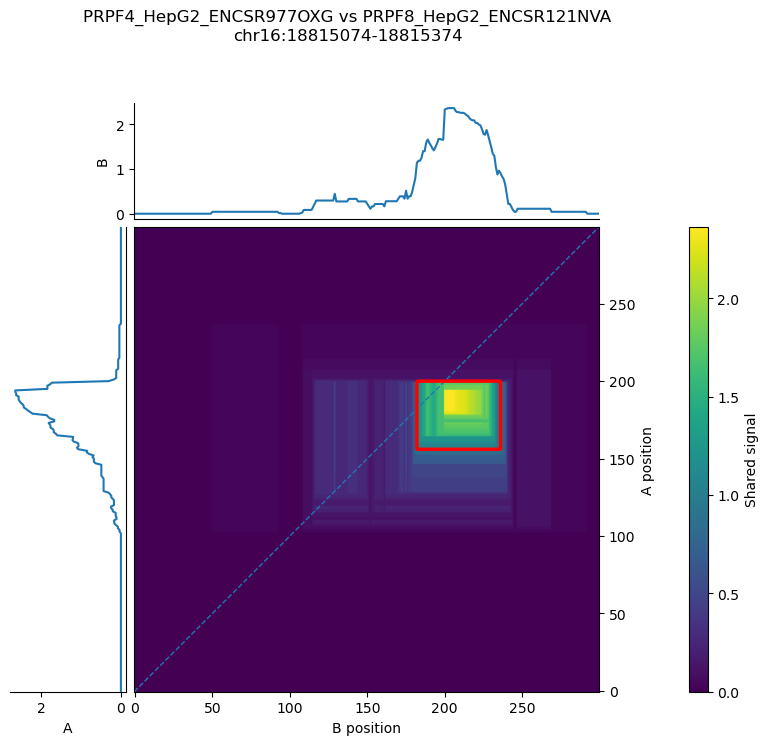

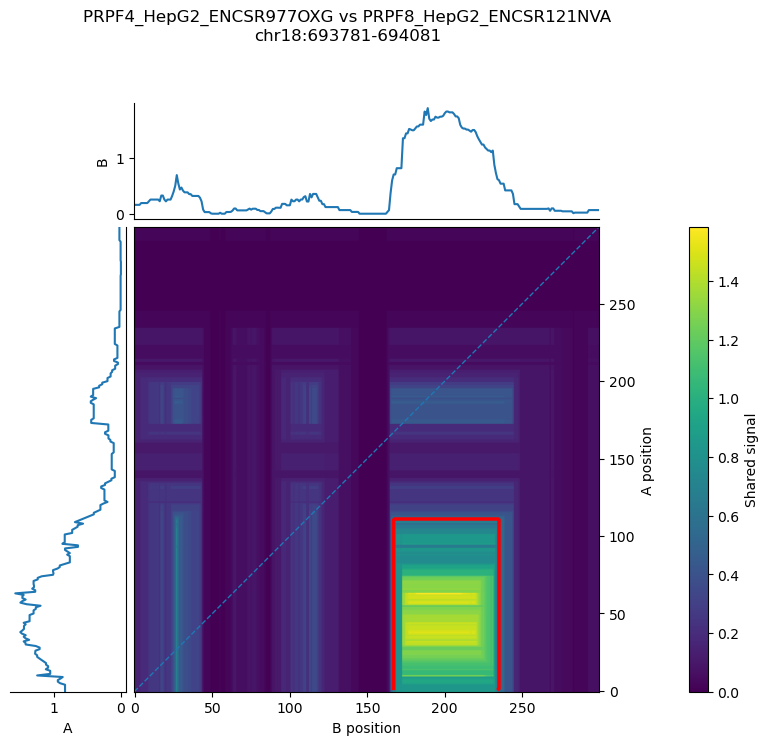

In [77]:
plot_category("pure_displacement")

## Shuffled offscreen

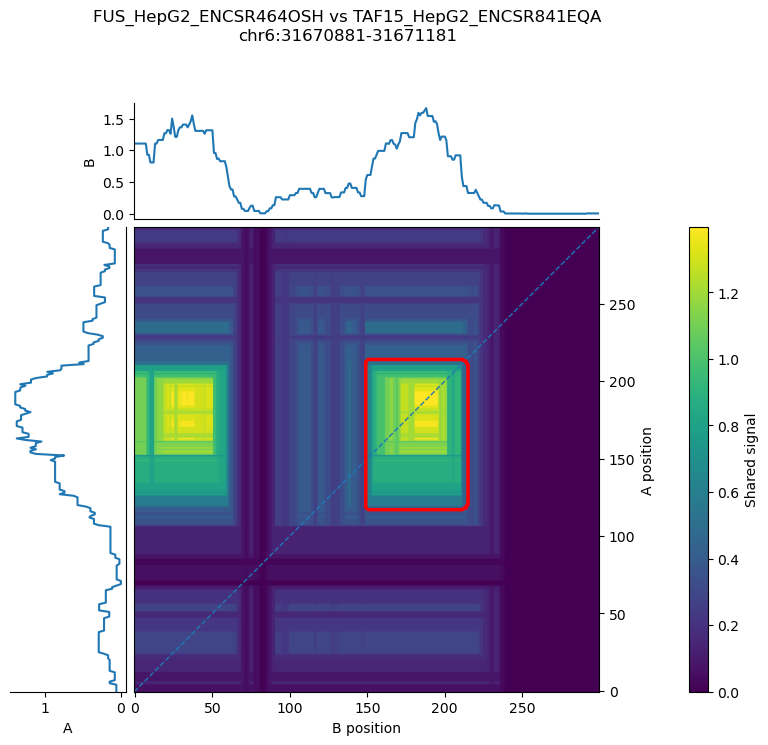

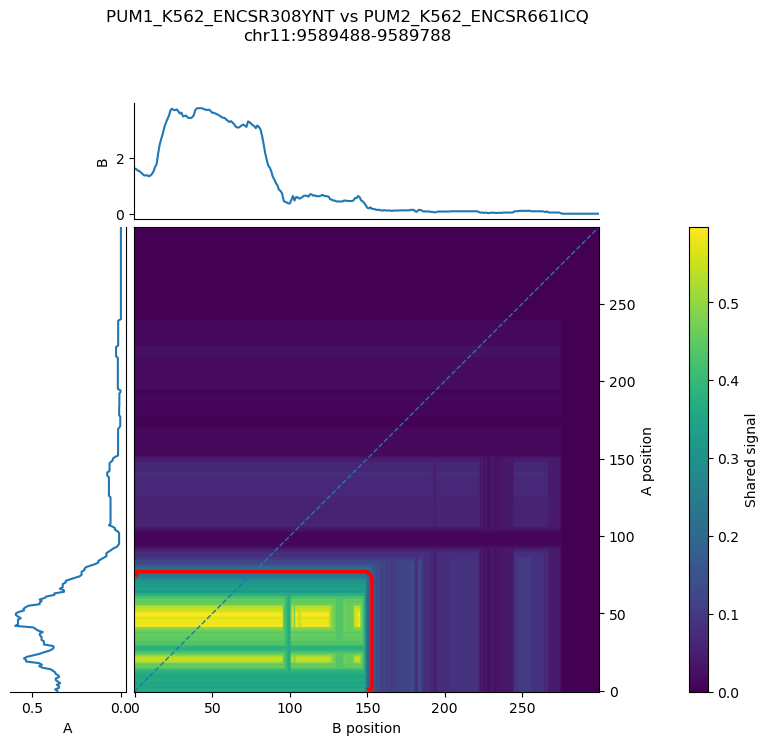

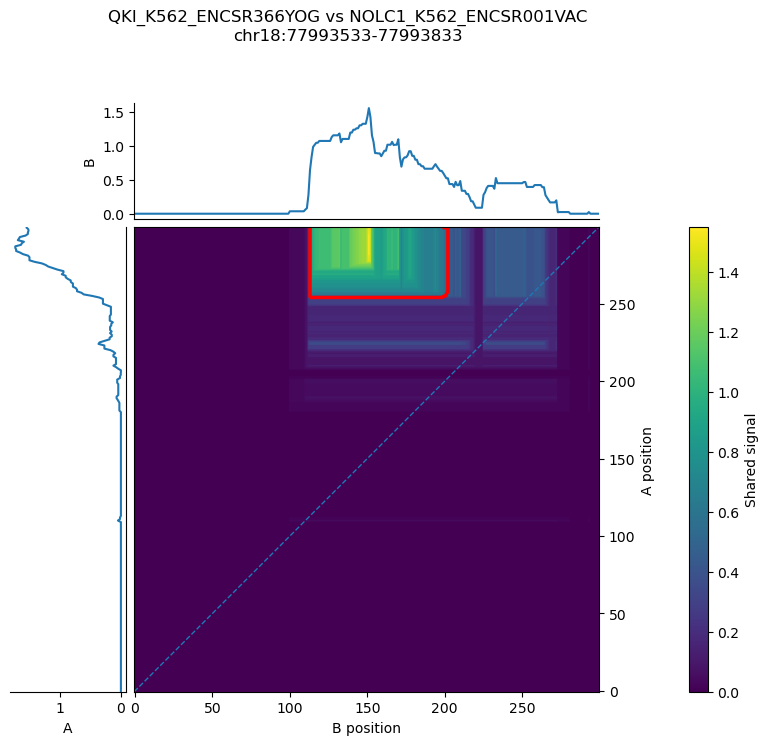

In [50]:
plot_category("shuffled_off_screen")

## Noisy

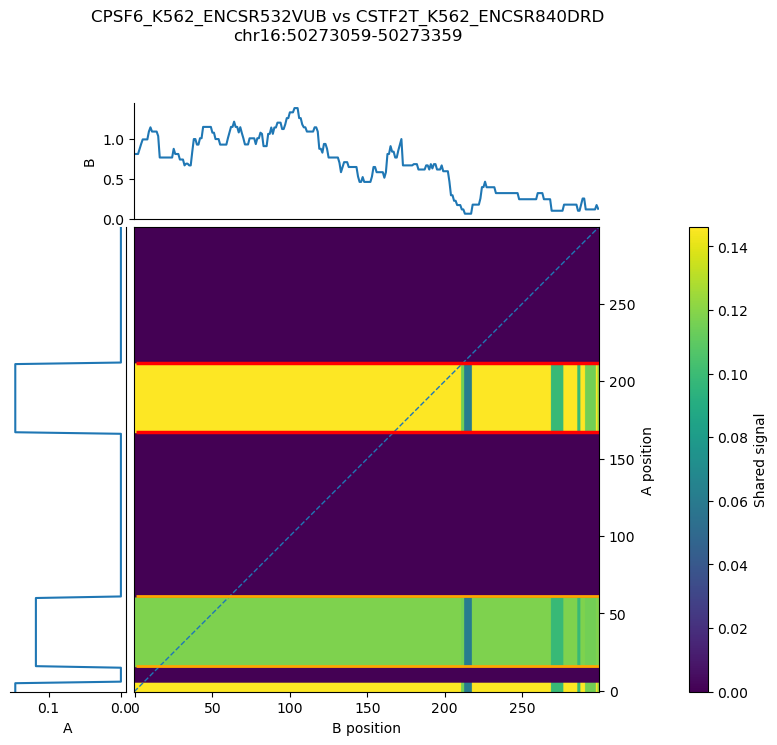

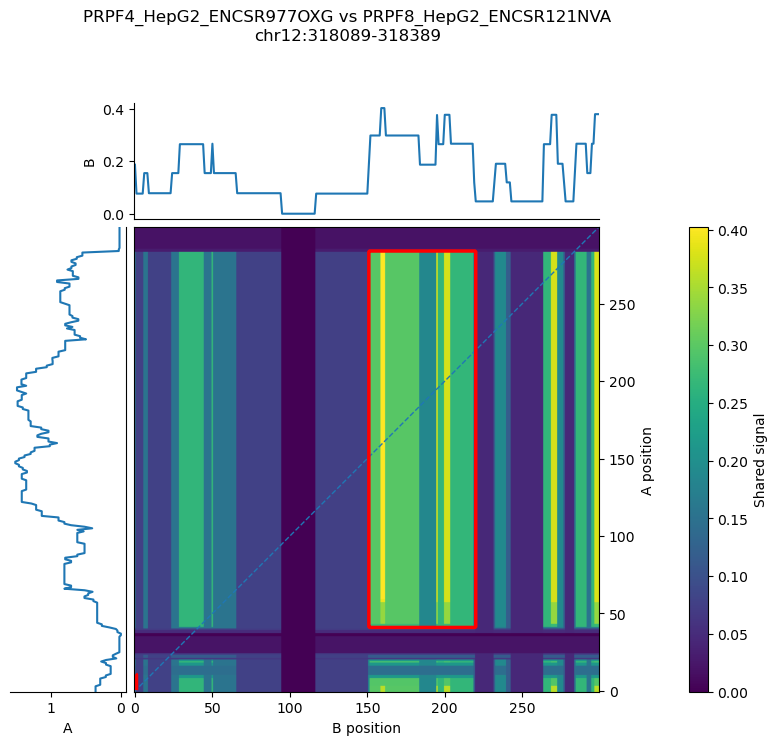

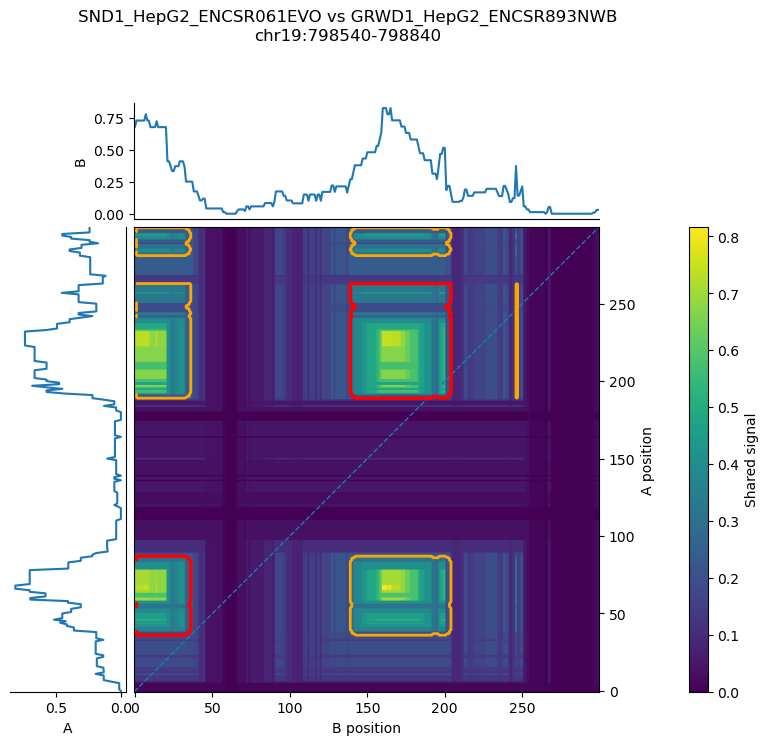

In [51]:
plot_category("noisy")

# Notes

- Of course it is an alignment problem. As a bioinformatician, how did I never think of that before? Did Pavel teach me nothing? I might actually have to look back at some old material for that, may be some useful notes, or stuff that can speed up the problem. 

- That first one I looked at brings up an interesting complex. Let's assume we select that main one as being the main one. In that case, we know for a FACT that there is only one other option for the second one. Like, there are those little bits at the ends that

- The noisy bits show off a meaningful problem with this definition of the best window, which is that it means that things close to the 0 line and far off the zero line are treated as equals. 

In [21]:
noisy_records = []

subset = metadata[
    metadata["zoo_category"] == "noisy"
]

for _, row in subset.iterrows():

    comp = comparison_data[row["comparison_id"]]
    window_idx = row["window_idx"]

    islands = comp["islands"][window_idx]
    roles = comp["island_roles"][window_idx]

    for island in islands:

        island_id = island["island_id"]

        noisy_records.append({
            "experiment_A": row["experiment_A"],
            "experiment_B": row["experiment_B"],
            "window": (
                f'{row["chrom"]}:'
                f'{row["start"]}-'
                f'{row["end"]}'
            ),

            "island_id": island_id,
            "role": roles.get(island_id, "unknown"),

            "total_support": island["total_support"],
            "mean_support": island["mean_support"],
            "max_support": island["max_support"],
            "area": island["area"],

            "A_width": island["A_width"],
            "B_width": island["B_width"],

            "A_center": island["A_center"],
            "B_center": island["B_center"],

            "zero_lag_distance": island[
                "zero_lag_distance"
            ],
        })

noisy_islands_df = pd.DataFrame(noisy_records)

noisy_islands_df

,experiment_A,experiment_B,window,island_id,role,total_support,mean_support,max_support,area,A_width,B_width,A_center,B_center,zero_lag_distance
0,CPSF6_K562_ENCSR532VUB,CSTF2T_K562_ENCSR840DRD,chr16:50273059-50273359,1,ignored,255.756836,0.142087,0.146106,1800,6,300,2.5,149.5,0.0
1,CPSF6_K562_ENCSR532VUB,CSTF2T_K562_ENCSR840DRD,chr16:50273059-50273359,2,alternative,1565.132812,0.115936,0.117597,13500,45,300,38.0,149.5,0.0
2,CPSF6_K562_ENCSR532VUB,CSTF2T_K562_ENCSR840DRD,chr16:50273059-50273359,3,main,1918.176392,0.142087,0.146106,13500,45,300,189.0,149.5,0.0
3,PRPF4_HepG2_ENCSR977OXG,PRPF8_HepG2_ENCSR121NVA,chr12:318089-318389,1,co-main,32.381210,0.097828,0.186739,331,25,14,12.0,6.5,0.0
4,PRPF4_HepG2_ENCSR977OXG,PRPF8_HepG2_ENCSR121NVA,chr12:318089-318389,2,main,191.146927,0.149334,0.266580,1280,25,52,12.0,44.5,7.0
5,PRPF4_HepG2_ENCSR977OXG,PRPF8_HepG2_ENCSR121NVA,chr12:318089-318389,3,deleted,350.889832,0.190805,0.361301,1839,25,74,12.0,182.5,134.0
6,PRPF4_HepG2_ENCSR977OXG,PRPF8_HepG2_ENCSR121NVA,chr12:318089-318389,4,deleted,39.669487,0.146382,0.190270,271,25,11,12.0,237.0,213.0
7,PRPF4_HepG2_ENCSR977OXG,PRPF8_HepG2_ENCSR121NVA,chr12:318089-318389,5,deleted,65.952637,0.188976,0.361301,349,25,14,12.0,270.5,246.5
8,PRPF4_HepG2_ENCSR977OXG,PRPF8_HepG2_ENCSR121NVA,chr12:318089-318389,6,deleted,75.165466,0.189812,0.361301,396,25,16,12.0,291.5,267.5
9,PRPF4_HepG2_ENCSR977OXG,PRPF8_HepG2_ENCSR121NVA,chr12:318089-318389,7,deleted,346.819183,0.101587,0.186739,3414,244,14,161.5,6.5,33.5


In [22]:
gate_records = []

for _, row in subset.iterrows():

    comp = comparison_data[row["comparison_id"]]
    window_idx = row["window_idx"]

    records = comp[
        "zero_lag_gate_records"
    ][window_idx]

    for record in records:

        gate_records.append({
            "experiment_A": row["experiment_A"],
            "experiment_B": row["experiment_B"],
            "window": (
                f'{row["chrom"]}:'
                f'{row["start"]}-'
                f'{row["end"]}'
            ),
            **record
        })

noisy_gate_df = pd.DataFrame(gate_records)

noisy_gate_df

,experiment_A,experiment_B,window,island_id,status,reason,island_support,strongest_zero_island,zero_support,required_support,support_ratio
0,PRPF4_HepG2_ENCSR977OXG,PRPF8_HepG2_ENCSR121NVA,chr12:318089-318389,3,deleted,failed_zero_lag_gate,350.889832,9.0,4734.121094,9468.242188,0.074119
1,PRPF4_HepG2_ENCSR977OXG,PRPF8_HepG2_ENCSR121NVA,chr12:318089-318389,4,deleted,failed_zero_lag_gate,39.669487,10.0,439.865479,879.730957,0.090186
2,PRPF4_HepG2_ENCSR977OXG,PRPF8_HepG2_ENCSR121NVA,chr12:318089-318389,5,deleted,failed_zero_lag_gate,65.952637,11.0,898.427063,1796.854126,0.073409
3,PRPF4_HepG2_ENCSR977OXG,PRPF8_HepG2_ENCSR121NVA,chr12:318089-318389,6,deleted,failed_zero_lag_gate,75.165466,12.0,1006.855652,2013.711304,0.074654
4,PRPF4_HepG2_ENCSR977OXG,PRPF8_HepG2_ENCSR121NVA,chr12:318089-318389,7,deleted,failed_zero_lag_gate,346.819183,9.0,4734.121094,9468.242188,0.073259
5,SND1_HepG2_ENCSR061EVO,GRWD1_HepG2_ENCSR893NWB,chr19:798540-798840,1,survived,no_zero_lag_conflict,885.142090,NaN,NaN,NaN,NaN
6,SND1_HepG2_ENCSR061EVO,GRWD1_HepG2_ENCSR893NWB,chr19:798540-798840,2,survived,no_zero_lag_conflict,1491.268921,NaN,NaN,NaN,NaN
7,SND1_HepG2_ENCSR061EVO,GRWD1_HepG2_ENCSR893NWB,chr19:798540-798840,3,deleted,failed_zero_lag_gate,55.987076,6.0,78.477394,156.954788,0.713417
8,SND1_HepG2_ENCSR061EVO,GRWD1_HepG2_ENCSR893NWB,chr19:798540-798840,4,survived,passed_zero_lag_gate,1251.543213,6.0,78.477394,156.954788,15.947818
9,SND1_HepG2_ENCSR061EVO,GRWD1_HepG2_ENCSR893NWB,chr19:798540-798840,5,survived,passed_zero_lag_gate,2102.583984,6.0,78.477394,156.954788,26.792225


In [34]:
# Pull out the window.
row = metadata[
    (metadata["chrom"] == "chr20") &
    (metadata["start"] == 49284292) &
    (metadata["end"] == 49284592) &
    (metadata["experiment_A"] == "FUS_HepG2_ENCSR464OSH") &
    (metadata["experiment_B"] == "TAF15_HepG2_ENCSR841EQA")
].iloc[0]

comp = comparison_data[row["comparison_id"]]
window_idx = row["window_idx"]

# Central 300 nt, averaged across replicates.
core_size = 300
context = (comp["signal_A"].shape[2] - core_size) // 2
core_start = context
core_end = context + core_size

signal_A = comp["signal_A"][
    window_idx, :, core_start:core_end
].mean(axis=0)

signal_B = comp["signal_B"][
    window_idx, :, core_start:core_end
].mean(axis=0)

positions = np.arange(core_size)

# Get main island lag.
islands = comp["islands"][window_idx]
roles = comp["island_roles"][window_idx]

main_island = next(
    island
    for island in islands
    if roles.get(island["island_id"]) == "main"
)

lag = main_island["displacement"]

print(f"Lag: {lag} nt")

Lag: 17.5 nt


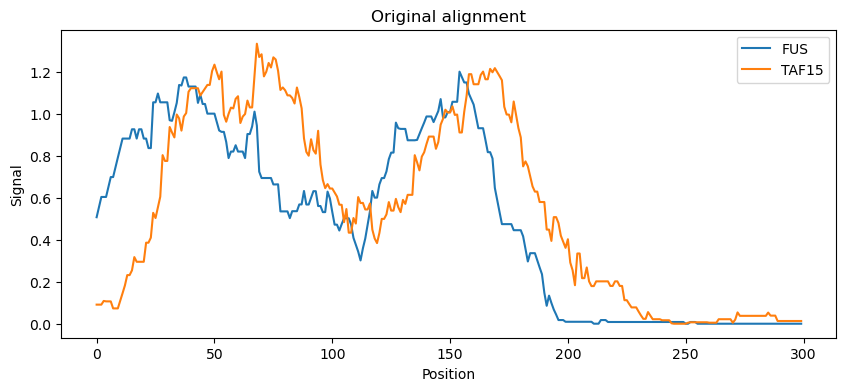

In [35]:
plt.figure(figsize=(10, 4))

plt.plot(positions, signal_A, label="FUS")
plt.plot(positions, signal_B, label="TAF15")

plt.xlabel("Position")
plt.ylabel("Signal")
plt.title("Original alignment")
plt.legend()

plt.show()

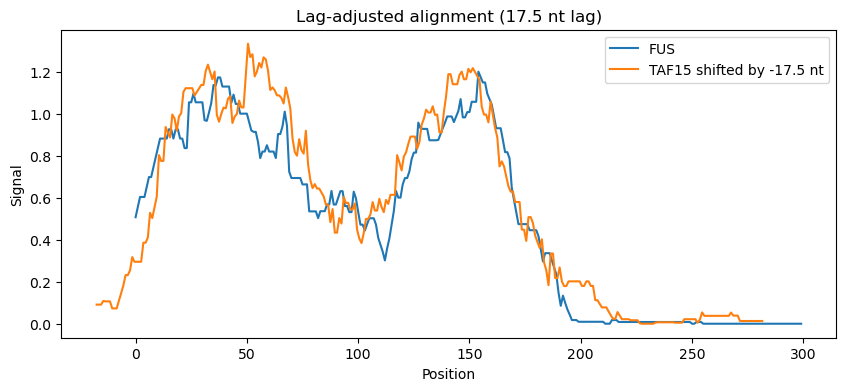

In [36]:
plt.figure(figsize=(10, 4))

plt.plot(positions, signal_A, label="FUS")
plt.plot(
    positions - lag,
    signal_B,
    label=f"TAF15 shifted by {-lag:g} nt"
)

plt.xlabel("Position")
plt.ylabel("Signal")
plt.title(f"Lag-adjusted alignment ({lag:g} nt lag)")
plt.legend()

plt.show()